# Análisis exploratorio

Se examinan `data/csv/set_A.csv` y `set_B.csv`. No se realiza limpieza ni preprocesamiento.

Cada fila representa una hora registrada de un paciente. Las observaciones repetidas de un mismo paciente no son independientes. La prevalencia de etiquetas positivas y los resúmenes demográficos se calculan por paciente; las distribuciones de mediciones utilizan los valores horarios observados, por lo que los pacientes con más mediciones tienen mayor peso.

## Configuraciones, librerías e importación de datos

In [1]:
from pathlib import Path
import hashlib
import platform
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "appr_project").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from appr_project.eda import (
    CLINICAL, DOCUMENTED_UNITS, compare_sets, integrity,
    load_sets, overview, patient_summary, unit_audit,
)
from appr_project.measurement_changes import (
    consecutive_absolute_changes, consecutive_percentage_changes,
    fit_mad_reference, label_mad_outliers,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLORS = {"A": "#256a91", "B": "#b75a32"}
print("Python:", platform.python_version(), "| pandas:", pd.__version__,
      "| NumPy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("Interpreter:", sys.executable)

Python: 3.13.14 | pandas: 3.1.0 | NumPy: 2.5.4 | matplotlib: 3.11.2
Interpreter: c:\Users\palom\Documents\College\APPR\APPR_project\.venv\Scripts\python.exe


In [2]:
paths = {s: ROOT / "data" / "csv" / f"set_{s}.csv" for s in ("A", "B")}
def sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

hashes_before = {s: sha256(p) for s, p in paths.items()}
display(pd.DataFrame([{"set": s, "file": str(p.relative_to(ROOT)),
                       "bytes": p.stat().st_size, "sha256": hashes_before[s]}
                      for s, p in paths.items()]))
sets = load_sets(ROOT / "data" / "csv")

,set,file,bytes,sha256
0,A,data\csv\set_A.csv,134750472,d83e36b7dd470591a886bdb572277e9ee1c3baff191f3f...
1,B,data\csv\set_B.csv,126793044,9d913ecccc8a55dadb03c8309c39eef03fbd1474a0eb25...


## 1. Inspección inicial de los conjuntos, pacientes y tipos

Los hashes identifican los archivos exactos utilizados y se verifican de nuevo al final. Los CSV contienen 41 columnas originales y dos columnas de metadatos añadidas durante la extracción. `source_set` identifica el conjunto de origen; no es una medición clínica.

In [3]:
assert list(sets["A"].columns) == list(sets["B"].columns) == list(DOCUMENTED_UNITS)
patients = {s: patient_summary(frame) for s, frame in sets.items()}
patients['A'].head(10)

,rows,first_hour,last_hour,septic,age,gender,hosp_adm_time,first_positive_hour
patient_id,,,,,,,,
A_000001,54,1,54,0,83.14,0,-0.03,NaN
A_000002,23,1,23,0,75.91,0,-98.6,NaN
A_000003,48,1,48,0,45.82,0,"-1,196",NaN
A_000004,29,1,29,0,65.71,0,-8.77,NaN
A_000005,48,2,49,0,28.09,1,-0.05,NaN
A_000006,17,3,19,0,52.01,1,-0.03,NaN
A_000007,45,1,45,0,64.24,1,-0.05,NaN
A_000008,40,1,40,0,87.08,1,-2.23,NaN
A_000009,258,1,258,1,27.92,1,-0.03,249


In [4]:
cohort = overview(sets, patients)
display(cohort)

,rows,columns,patients,septic_patients,septic_patient_pct,positive_row_pct,median_recorded_hours,median_patient_age,female_patient_pct,clinical_missing_pct
source_set,,,,,,,,,,
A,790215,43,20336,1790,8.802,2.169,39,64.67,41.81,79.39
B,761995,43,20000,1142,5.71,1.415,38,62,46.34,80.89


`Age` es la única columna con tipos diferentes en ambos conjuntos: en el conjunto A es flotante, y en el B es entero.

In [5]:
print("Patient ID overlap:", len(set(patients["A"].index) & set(patients["B"].index)))
print("Types:")
display(pd.DataFrame({s: f.dtypes.astype(str) for s, f in sets.items()}))

Patient ID overlap: 0
Types:


,A,B
HR,float64,float64
O2Sat,float64,float64
Temp,float64,float64
SBP,float64,float64
MAP,float64,float64
DBP,float64,float64
Resp,float64,float64
EtCO2,float64,float64
BaseExcess,float64,float64
HCO3,float64,float64


## 2. Verificación de unidades de medida y valores inválidos

Las unidades publicadas se transcriben de [PhysioNet v1.0.0](https://physionet.org/content/challenge-2019/1.0.0/) (consulta: 2026-10-22). Los CSV contienen números sin metadatos de unidades para cada medición. Una distribución puede contradecir una escala declarada o motivar una hipótesis, pero **no permite confirmar la unidad de cada valor**.

La siguiente tabla incluye todas las columnas, la cantidad de valores observados, los porcentajes de datos faltantes por fila y de pacientes sin ningún registro de la variable (`missing_pct_patients`), el rango, los percentiles y verificaciones amplias del dominio. Las variables sin observaciones se señalan como no evaluables. Las alertas de dominio son recuentos diagnósticos, no criterios para eliminar filas. No se impone un rango clínico de referencia a los pacientes de UCI.

In [6]:
audit = unit_audit(sets)
with pd.option_context("display.max_columns", None, "display.max_colwidth", 110):
    for s in ("A", "B"):
        print(f"SET {s}: all {len(DOCUMENTED_UNITS)} columns")
        display(audit.loc[audit.source_set.eq(s)].set_index("column").drop(columns="source_set"))

SET A: all 43 columns


,documented_unit,n_observed,missing_pct,missing_pct_patients,dtype,min,p01,q1,median,q3,p99,max,n_infinite,n_domain_flags,assessment
column,,,,,,,,,,,,,,,
HR,beats/min,729026,7.743,0.004917,float64,20,51,73,84,96,129.5,280,0,0,Scale not contradicted by this audit.
O2Sat,%,695136,12.03,0.05901,float64,20,89,96,98,99.5,100,100,0,0,"Checked percentage bounds [0,100]; fraction-scale mixing cannot be excluded."
Temp,°C,266901,66.22,1.156,float64,20.9,35.11,36.56,37.06,37.55,38.83,42.22,0,0,Scale not contradicted by this audit.
SBP,mmHg,670014,15.21,1.269,float64,22,81,105,118.5,134,179,281,0,0,Scale not contradicted by this audit.
MAP,mmHg,709357,10.23,0.009835,float64,20,50.67,68,77,87.33,120,300,0,0,Scale not contradicted by this audit.
DBP,mmHg,409918,48.13,36.31,float64,20,36,51,58.5,67,96,298,0,0,Scale not contradicted by this audit.
Resp,breaths/min,712957,9.777,0.1377,float64,1,9,15,18,22,35,69,0,0,Scale not contradicted by this audit.
EtCO2,mmHg,0,100,100,float64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,No observed values: unit/scale cannot be assessed for this set.
BaseExcess,mmol/L,82381,89.57,37.79,float64,-32,-13,-3,0,1,11,100,0,0,Scale not contradicted by this audit.


SET B: all 43 columns


,documented_unit,n_observed,missing_pct,missing_pct_patients,dtype,min,p01,q1,median,q3,p99,max,n_infinite,n_domain_flags,assessment
column,,,,,,,,,,,,,,,
HR,beats/min,669785,12.1,0.02,float64,20,49,71.5,83,95,131,211,0,0,Scale not contradicted by this audit.
O2Sat,%,654338,14.13,0.03,float64,20,89,96,98,99.5,100,100,0,0,"Checked percentage bounds [0,100]; fraction-scale mixing cannot be excluded."
Temp,°C,258325,66.1,0.245,float64,30,35.1,36.5,36.9,37.4,38.8,50,0,0,Scale not contradicted by this audit.
SBP,mmHg,655931,13.92,0.12,float64,20,80,109,124,142,191,300,0,0,Scale not contradicted by this audit.
MAP,mmHg,649583,14.75,0.51,float64,30,56,74.5,84,96,133,300,0,0,Scale not contradicted by this audit.
DBP,mmHg,655738,13.94,0.135,float64,20,39,56,65,74,106,300,0,0,Scale not contradicted by this audit.
Resp,breaths/min,600918,21.14,0.215,float64,1,10,16,18,21,33,100,0,0,Scale not contradicted by this audit.
EtCO2,mmHg,57636,92.44,83.92,float64,10,13,28,33,38,52,100,0,0,Scale not contradicted by this audit.
BaseExcess,mmol/L,1764,99.77,97.21,float64,-23.2,-15.04,-4.9,-2.4,-0.2,7.337,14.2,0,0,Scale not contradicted by this audit.


## 3. Integridad estructural y temporal

Se cuentan los duplicados de paciente-hora, los pasos horarios distintos de una hora y las reversiones de `SepsisLabel` de 1 a 0, sin ordenar ni corregir los datos. Los valores positivos de `HospAdmTime` y la codificación de `Age` se examinan por separado. La constancia de los datos demográficos se evalúa únicamente sobre los valores observados; los datos faltantes se describen en otras tablas.

También se resume la primera hora registrada de los pacientes que no empiezan en `ICULOS = 1`. Una secuencia horaria continua puede empezar tarde: la cantidad de filas disponibles no equivale necesariamente a la estancia completa en UCI.

In [7]:
checks = integrity(sets)
display(checks)

,missing_patient_id,duplicate_patient_hour,non_unit_hour_steps,patients_not_starting_at_1,label_reversals,positive_hospital_admission_rows,changing_demographics_patients,infinite_numeric_values
source_set,,,,,,,,
A,0,0,0,7497,0,8513,0,0
B,0,0,0,1296,0,0,0,0


In [8]:
summary_patients_not_starting_at_1 = {}

for s, frame in sets.items():
    first = frame.groupby("patient_id", sort=False)["ICULOS"].first()
    summary_patients_not_starting_at_1[s] = first[first.ne(1)].describe()

display(pd.DataFrame(summary_patients_not_starting_at_1).T.rename_axis("source_set"))

,count,mean,std,min,25%,50%,75%,max
source_set,,,,,,,,
A,"7,497",3.485,6.029,2,2,3,4,304
B,"1,296",3.059,1.887,2,2,2,4,26


En B se observan pacientes menores de 18 años y registros con `Age = 100`, pero ninguno con `90 ≤ Age < 100` ni con edades superiores a 100. Según la documentación, 100 representa la codificación de edades de 90 años o más; no debe interpretarse como una edad exacta.

In [9]:
for s, frame in sets.items():
    g = frame.groupby("patient_id", sort=False)
    print(f"Set {s}: patients with changing observed administrative/demographic values")
    display(g[["Age", "Gender", "Unit1", "Unit2", "HospAdmTime"]]
            .nunique(dropna=True).gt(1).sum().rename("patient_count").to_frame())
    p = patients[s]
    display(pd.Series({"patients_age_100": int(p.age.eq(100).sum()),
                       "patients_90_to_below_100": int(p.age.between(90, 100, inclusive="left").sum()),
                       "patients_below_18": int(p.age.lt(18).sum()),
                       "minimum_patient_age": p.age.min(),
                       "maximum_patient_age": p.age.max()}, name=s).to_frame())

Set A: patients with changing observed administrative/demographic values


,patient_count
Age,0
Gender,0
Unit1,0
Unit2,0
HospAdmTime,0


,A
patients_age_100,0
patients_90_to_below_100,0
patients_below_18,0
minimum_patient_age,18.11
maximum_patient_age,89


Set B: patients with changing observed administrative/demographic values


,patient_count
Age,0
Gender,0
Unit1,0
Unit2,0
HospAdmTime,0


,B
patients_age_100,392
patients_90_to_below_100,0
patients_below_18,22
minimum_patient_age,14
maximum_patient_age,100


## 4. Datos faltantes y disponibilidad de mediciones

Se comparan tanto los datos faltantes por hora como el porcentaje de pacientes con al menos una medición observada. Este último es el complemento del porcentaje de pacientes sin ningún registro de la variable. La ausencia de una variable en un conjunto puede producir diferencias importantes entre A y B incluso cuando las unidades coinciden. Los valores faltantes nunca se interpretan como ceros.

El porcentaje global de datos clínicos faltantes abarca las 34 variables de signos vitales y laboratorio; excluye datos demográficos, tiempos, identificadores y la variable objetivo.

,unit,n_A,n_B,missing_A_pct,missing_B_pct,median_A,median_B,missing_B_minus_A_pp,median_B_minus_A
column,,,,,,,,,
DBP,mmHg,409918,655738,48.13,13.94,58.5,65,-34.18,6.5
Unit2,SICU administrative indicator,404050,536200,48.87,29.63,0,1,-19.24,1
Unit1,MICU administrative indicator,404050,536200,48.87,29.63,1,0,-19.24,-1
FiO2,%,112155,17210,85.81,97.74,0.5,0.4,11.93,-0.1
Resp,breaths/min,712957,600918,9.777,21.14,18,18,11.36,0
BaseExcess,mmol/L,82381,1764,89.57,99.77,0,-2.4,10.19,-2.4
Glucose,mg/dL,96656,168860,87.77,77.84,124,128,-9.929,4
pH,dimensionless,90615,16958,88.53,97.77,7.39,7.38,9.242,-0.01
HCO3,mmol/L,63617,1411,91.95,99.81,24,23.4,7.865,-0.6


,A_patient_observed_pct,B_patient_observed_pct
HR,100,99.98
O2Sat,99.94,99.97
Temp,98.84,99.76
SBP,98.73,99.88
MAP,99.99,99.49
DBP,63.69,99.87
Resp,99.86,99.78
EtCO2,0,16.08
BaseExcess,62.21,2.79
HCO3,97.37,2.08


Entirely unobserved columns:


,source_set,column
7,A,EtCO2


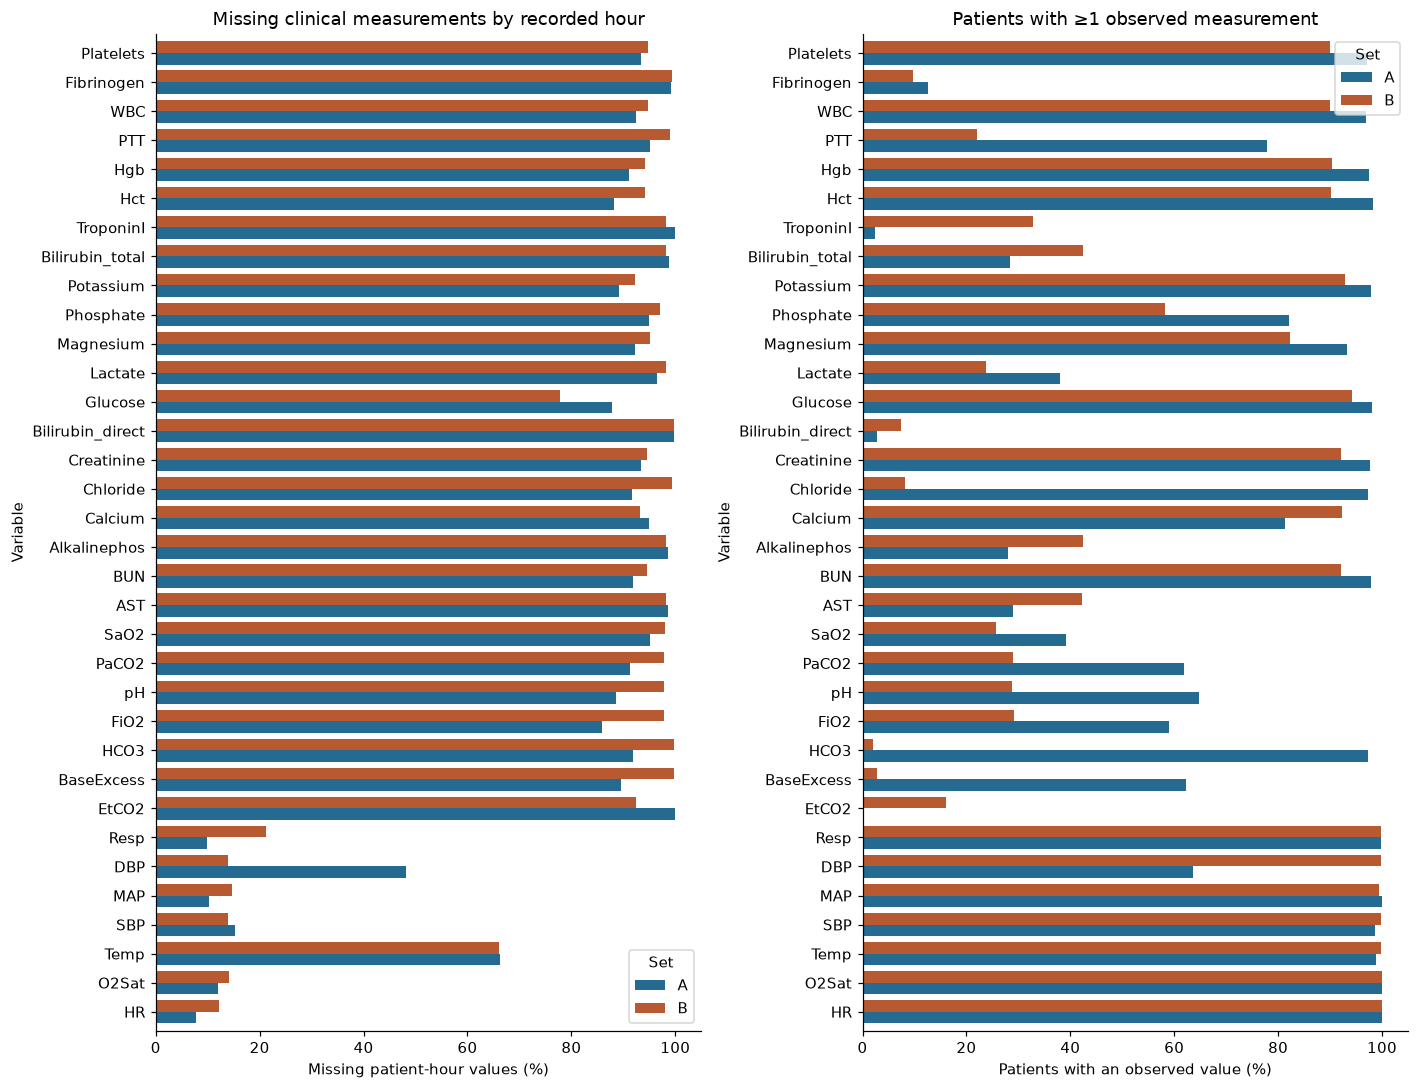

In [10]:
comparison = compare_sets(audit)
display(comparison.sort_values("missing_B_minus_A_pp", key=abs, ascending=False))
availability = pd.DataFrame({
    s: frame.groupby("patient_id", sort=False)[CLINICAL].count().gt(0).mean() * 100
    for s, frame in sets.items()
})
availability.columns = ["A_patient_observed_pct", "B_patient_observed_pct"]
display(availability)
all_missing = audit.loc[audit.n_observed.eq(0), ["source_set", "column"]]
print("Entirely unobserved columns:")
display(all_missing)

fig, axes = plt.subplots(1, 2, figsize=(13, 10))
missing = pd.DataFrame({s: f[CLINICAL].isna().mean() * 100 for s, f in sets.items()})
missing.plot.barh(ax=axes[0], color=[COLORS["A"], COLORS["B"]], width=.8)
axes[0].set(title="Missing clinical measurements by recorded hour",
            xlabel="Missing patient-hour values (%)", ylabel="Variable")
availability.plot.barh(ax=axes[1], color=[COLORS["A"], COLORS["B"]], width=.8)
axes[1].set(title="Patients with ≥1 observed measurement",
            xlabel="Patients with an observed value (%)", ylabel="Variable")
axes[0].legend(["A", "B"], title="Set")
axes[1].legend(["A", "B"], title="Set")
fig.tight_layout()
plt.show()

## 5. Composición de las cohortes, duración del registro y desbalance de la variable objetivo

Los resúmenes de edad y sexo utilizan el primer valor observado de cada paciente; las verificaciones anteriores identifican posibles cambios dentro del registro individual. Las «horas registradas» corresponden al número de filas y no garantizan la duración completa de la estancia hospitalaria o en UCI.

Para los pacientes con al menos un `SepsisLabel = 1`, se resumen la primera y la última hora registradas, la primera hora con etiqueta positiva y el porcentaje de horas registradas con etiqueta positiva. Este porcentaje usa como denominador las filas disponibles de cada paciente, no todas las horas de su estancia real.

La primera hora positiva es una **marca temporal de la etiqueta de alerta temprana**, no la hora de inicio clínico de la sepsis: el desafío adelanta las etiquetas seis horas respecto al inicio definido. Si el primer registro ya es positivo, no se observa la transición previa dentro del archivo.

In [11]:
sepsis_patients = {}

for s, frame in sets.items():
    groups = frame.groupby("patient_id", sort=False)

    summary = groups.agg(
        first_recorded_hour=("ICULOS", "min"),
        last_recorded_hour=("ICULOS", "max"),
        pct_hours_with_sepsis=("SepsisLabel", lambda x: 100 * x.mean()),
    )

    summary["first_sepsis_hour"] = (
        frame.loc[frame["SepsisLabel"].eq(1)]
        .groupby("patient_id")["ICULOS"]
        .min()
    )

    sepsis_patients[s] = summary.loc[
        summary["first_sepsis_hour"].notna(),
        [
            "first_recorded_hour",
            "last_recorded_hour",
            "first_sepsis_hour",
            "pct_hours_with_sepsis",
        ],
    ]


sepsis_summary = pd.concat(sepsis_patients, names=["source_set"])

display(cohort[["septic_patients", "septic_patient_pct", "positive_row_pct",
                "median_recorded_hours", "median_patient_age", "female_patient_pct"]])

# Descriptive statistics by set
display(sepsis_summary.groupby(level="source_set")[["first_recorded_hour", "last_recorded_hour"]].describe())
display(sepsis_summary.groupby(level="source_set")[["first_sepsis_hour", "pct_hours_with_sepsis"]].describe())

,septic_patients,septic_patient_pct,positive_row_pct,median_recorded_hours,median_patient_age,female_patient_pct
source_set,,,,,,
A,1790,8.802,2.169,39,64.67,41.81
B,1142,5.71,1.415,38,62,46.34


first_recorded_hour                                  \
                         count  mean   std min 25% 50% 75% max   
source_set                                                       
A                        1,790 1.906 6.537   1   1   1   2 269   
B                        1,142 1.158 0.771   1   1   1   1  15   

           last_recorded_hour                                  
                        count  mean   std min 25% 50% 75% max  
source_set                                                     
A                       1,790 59.54 57.83   8  17  38  81 336  
B                       1,142 59.22 61.92   8  13  37  82 336

first_sepsis_hour                                    \
                       count  mean   std min  25%  50% 75% max   
source_set                                                       
A                      1,790 50.97 57.76   1    8 29.5  73 331   
B                      1,142 50.78 61.82   1 4.25 28.5  74 331   

           pct_hours_with_sepsis                                           
                           count  mean   std    min   25%   50%   75% max  
source_set                                                                 
A                          1,790 38.18 31.64  1.786 11.93 26.32 58.82 100  
B                          1,142 41.84 35.53 0.5988 11.37 26.02 76.92 100

In [12]:
for s, p in patients.items():
    print(f"Set {s}: patient-level summaries")
    display(p[["rows", "first_hour", "last_hour", "age", "hosp_adm_time",
               "first_positive_hour"]].describe(percentiles=[.01, .25, .5, .75, .99]).T)
    display(p.groupby("septic")[["rows", "age"]].agg(["count", "median", "mean"]))
    print("Patients with first positive label at their first recorded hour:",
          int((p.first_positive_hour.notna() & p.first_positive_hour.eq(p.first_hour)).sum()))

Set A: patient-level summaries


,count,mean,std,min,1%,25%,50%,75%,99%,max
rows,2.034e+04,38.86,22.31,8,9,25,39,47,132,336
first_hour,2.034e+04,1.916,3.852,1,1,1,1,2,8,304
last_hour,2.034e+04,39.77,22.55,8,10,26,40,48,134,336
age,2.034e+04,62.62,16.24,18.11,20.86,52.29,64.67,75.66,88.06,89
hosp_adm_time,2.034e+04,-48.68,143.7,"-3,711",-660.4,-34.13,-2.77,-0.02,0.7432,23.99
first_positive_hour,"1,790",50.97,57.76,1,1,8,29.5,73,247.2,331


rows                 age             
        count median  mean  count median  mean
septic                                        
0       18546     39 36.95  18546  64.64  62.6
1        1790     38 58.64   1790  65.19 62.84

Patients with first positive label at their first recorded hour: 203
Set B: patient-level summaries


,count,mean,std,min,1%,25%,50%,75%,99%,max
rows,2e+04,38.1,23.28,8,8,23,38,47,134,336
first_hour,2e+04,1.133,0.6983,1,1,1,1,1,4,26
last_hour,2e+04,38.23,23.27,8,9,23,38,47,134,336
age,2e+04,60.65,16.67,14,21,50,62,72,100,100
hosp_adm_time,2e+04,-55.07,135.6,"-5,367",-552.3,-52.35,-8.57,-3.38,0,0
first_positive_hour,"1,142",50.78,61.82,1,1,4.25,28.5,74,266,331


rows                 age             
        count median  mean  count median  mean
septic                                        
0       18858     38 36.83  18858     62 60.64
1        1142     37 59.06   1142     63 60.83

Patients with first positive label at their first recorded hour: 223


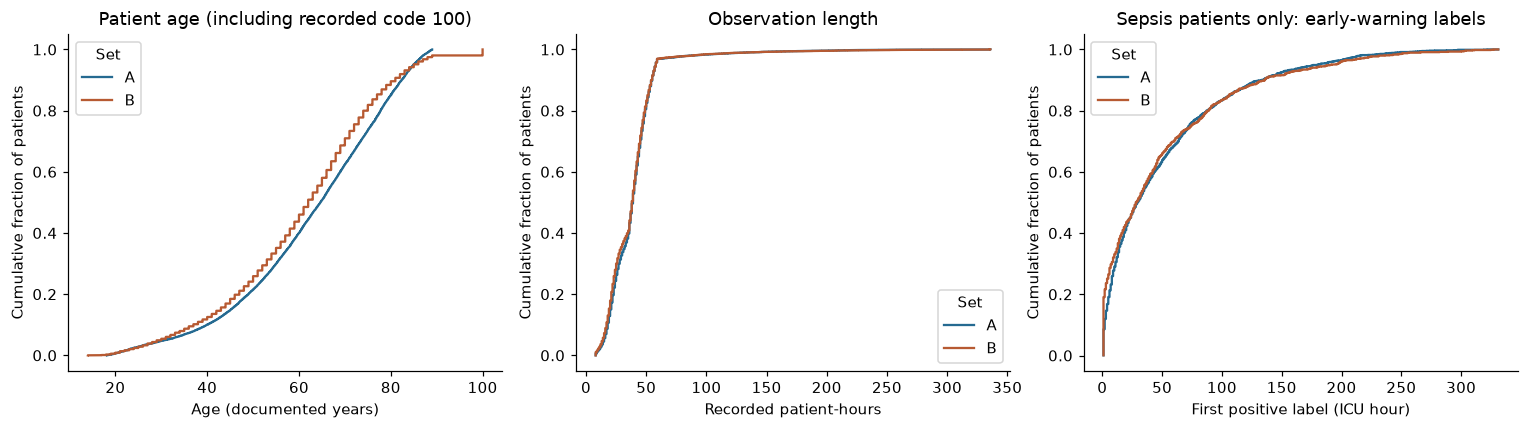

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for s, p in patients.items():
    for ax, col, label in zip(axes, ["age", "rows", "first_positive_hour"],
                               ["Age (documented years)", "Recorded patient-hours",
                                "First positive label (ICU hour)"]):
        x = p[col].dropna().sort_values().to_numpy()
        ax.step(x, np.arange(1, len(x) + 1) / len(x), label=s, color=COLORS[s])
        ax.set(xlabel=label, ylabel="Cumulative fraction of patients")
        ax.legend(title="Set")
axes[0].set_title("Patient age (including recorded code 100)")
axes[1].set_title("Observation length")
axes[2].set_title("Sepsis patients only: early-warning labels")
fig.tight_layout()
plt.show()

## 6. Diferencias de distribución entre las variables clínicas

Cada variable clínica observada se representa mediante su distribución acumulada empírica en todo el rango disponible. Los ejes `symlog` permiten conservar ceros, valores negativos y extremos. Las medianas y los cuantiles de la auditoría de unidades permanecen en la escala numérica original. La ausencia de una curva indica que no hay observaciones en ese conjunto.

Estas distribuciones se calculan **por medición**, de modo que la frecuencia de medición, la duración del registro y la composición de la cohorte pueden contribuir a las diferencias observadas. Las gráficas no aíslan un efecto del hospital.

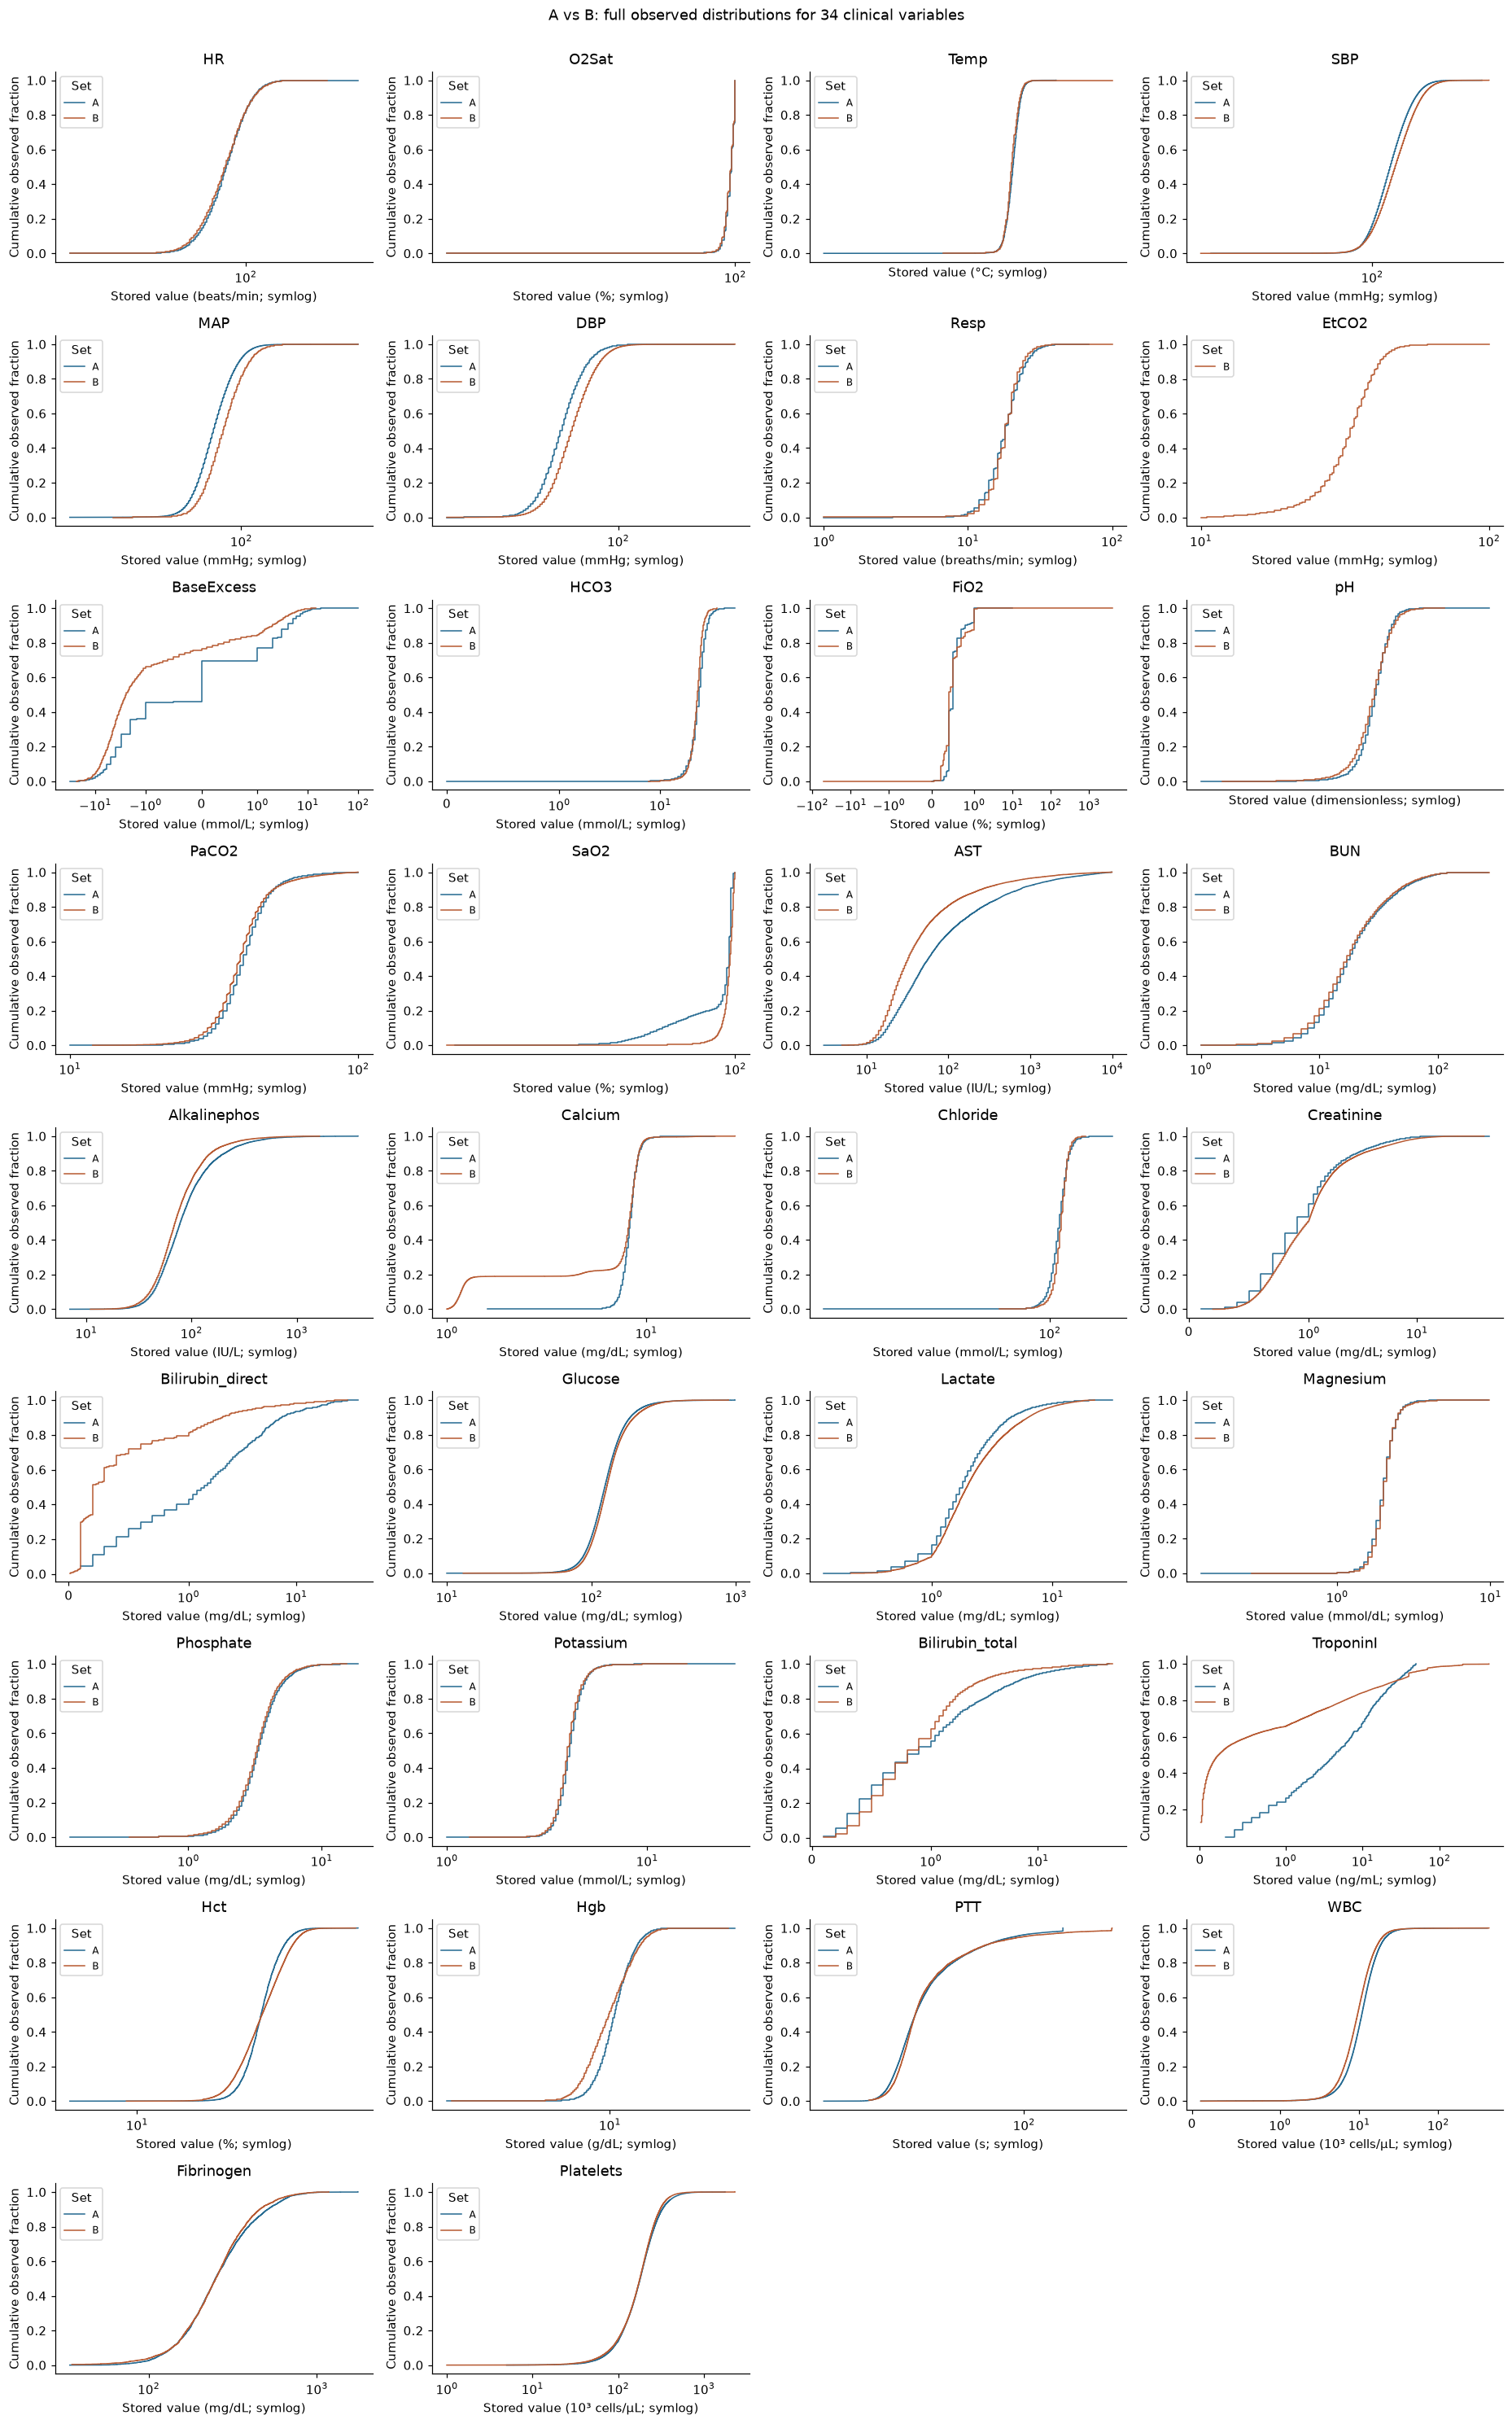

In [14]:
fig, axes = plt.subplots(9, 4, figsize=(17, 27))
for ax, col in zip(axes.flat, CLINICAL):
    for s, frame in sets.items():
        x = frame[col].dropna().sort_values().to_numpy()
        if len(x):
            # Keep the complete empirical support, including minimum and maximum.
            unique, counts = np.unique(x, return_counts=True)
            ax.step(unique, np.cumsum(counts) / counts.sum(), where="post",
                    label=s, color=COLORS[s], linewidth=1)
    ax.set_xscale("symlog", linthresh=1)
    ax.set(title=col, xlabel=f"Stored value ({DOCUMENTED_UNITS[col]}; symlog)",
           ylabel="Cumulative observed fraction")
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(title="Set", fontsize=8)
for ax in list(axes.flat)[len(CLINICAL):]:
    ax.set_visible(False)
fig.suptitle("A vs B: full observed distributions for 34 clinical variables", y=1.001)
fig.tight_layout()
plt.show()

## 7. Asociaciones entre pares de variables y sus limitaciones

Las correlaciones de Spearman utilizan pares de mediciones observadas con un mínimo de 200 filas emparejadas. Los tamaños de muestra por par se calculan por separado. No se imputan valores faltantes. La disponibilidad conjunta puede variar considerablemente entre los conjuntos; las asociaciones son descriptivas y pueden reflejar mediciones repetidas, selección de pacientes y diferencias temporales. Una correlación `NaN` puede deberse a pocos pares disponibles o a una variable constante.

In [15]:
correlations = {}
for s, frame in sets.items():
    correlations[s] = frame[CLINICAL].corr(method="spearman", min_periods=200)
    observed = frame[CLINICAL].notna().astype("int64")
    paired_n = observed.T.dot(observed)
    # print(f"Set {s}: number of jointly observed hourly values per pair")
    # display(paired_n)

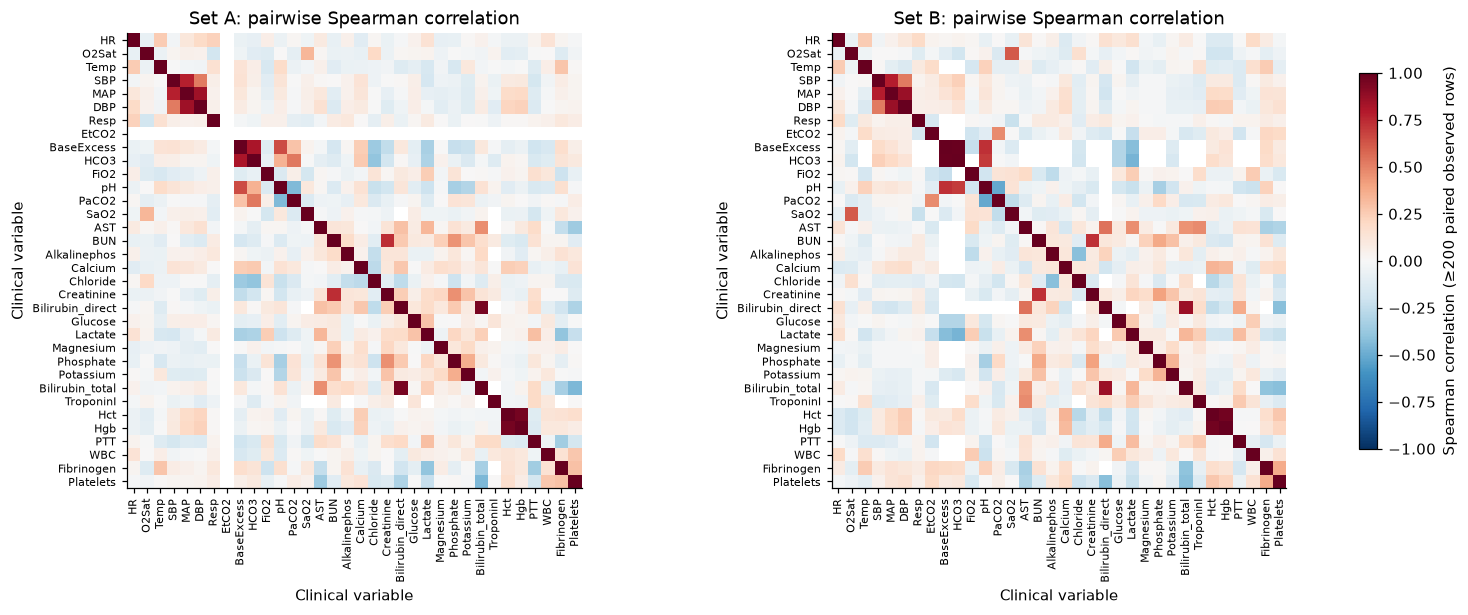

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for ax, s in zip(axes, ["A", "B"]):
    im = ax.imshow(correlations[s], vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(CLINICAL)), CLINICAL, rotation=90, fontsize=7)
    ax.set_yticks(range(len(CLINICAL)), CLINICAL, fontsize=7)
    ax.set(title=f"Set {s}: pairwise Spearman correlation", xlabel="Clinical variable",
           ylabel="Clinical variable")
fig.subplots_adjust(wspace=.55, bottom=.27)
fig.colorbar(im, ax=axes, label="Spearman correlation (≥200 paired observed rows)", shrink=.7)
plt.show()

## 8. Pacientes observados y proporción de etiquetas positivas por hora de UCI

Las gráficas muestran las horas 1–72 únicamente como ventana de visualización; las demás tablas y verificaciones utilizan los datos completos. Se presenta el número de pacientes registrados en cada hora junto con el porcentaje de filas con etiqueta positiva. Las horas posteriores representan una población seleccionada que continúa apareciendo en los registros; los cambios en la proporción de etiquetas positivas no equivalen por sí solos a cambios en la incidencia de sepsis.

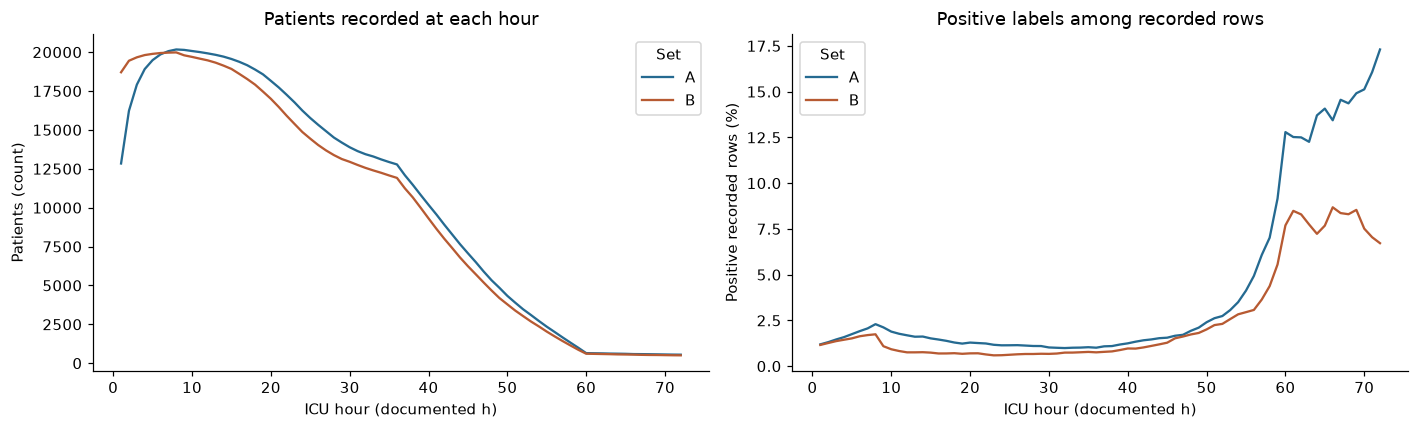

In [17]:
hourly = {}
for s, frame in sets.items():
    group = frame.groupby("ICULOS")
    hourly[s] = pd.DataFrame({
        "recorded_patients": group.patient_id.nunique(),
        "positive_label_pct": group.SepsisLabel.mean() * 100,
    })
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title, unit in zip(
    axes.flat,
    ["recorded_patients", "positive_label_pct"],
    ["Patients recorded at each hour", "Positive labels among recorded rows"],
    ["Patients (count)", "Positive recorded rows (%)"],
):
    for s in ("A", "B"):
        view = hourly[s].loc[1:72]
        ax.plot(view.index, view[col], label=s, color=COLORS[s])
    ax.set(title=title, xlabel="ICU hour (documented h)", ylabel=unit)
    ax.legend(title="Set")
fig.tight_layout()
plt.show()

## 9. Síntesis reproducible de resultados y preguntas pendientes

El siguiente resumen se calcula a partir de los datos cargados y de los resultados de las secciones anteriores. Distingue pacientes, filas horarias y mediciones observadas. Las diferencias de datos faltantes se expresan en puntos porcentuales, B menos A.

Se reúnen la composición de las cohortes, la ausencia de mediciones por fila y por paciente, las variables que requieren aclarar su escala, la integridad temporal y los tiempos de los pacientes con etiquetas positivas. Las comparaciones son descriptivas: combinan prácticas de registro, disponibilidad de mediciones y diferencias entre poblaciones.

In [18]:
# Resultados de las secciones 1 y 5: población y etiquetas.
print("Composición de las cohortes y frecuencia de etiquetas positivas:")
display(cohort)

Composición de las cohortes y frecuencia de etiquetas positivas:


,rows,columns,patients,septic_patients,septic_patient_pct,positive_row_pct,median_recorded_hours,median_patient_age,female_patient_pct,clinical_missing_pct
source_set,,,,,,,,,,
A,790215,43,20336,1790,8.802,2.169,39,64.67,41.81,79.39
B,761995,43,20000,1142,5.71,1.415,38,62,46.34,80.89


In [19]:

# Resultados de las secciones 2 y 4: denominadores por fila y por paciente.
comparison = compare_sets(audit)
print("\nMayores diferencias de datos faltantes por fila (B − A, puntos porcentuales):")
display(comparison.loc[CLINICAL].sort_values(
    "missing_B_minus_A_pp", key=abs, ascending=False
).head(10))

patient_missing_summary = audit.loc[
    audit.column.isin(CLINICAL),
    ["source_set", "column", "missing_pct", "missing_pct_patients"],
].pivot(index="column", columns="source_set",
        values=["missing_pct", "missing_pct_patients"])
patient_missing_summary[("diferencia_pacientes_pp", "B menos A")] = (
    patient_missing_summary[("missing_pct_patients", "B")]
    - patient_missing_summary[("missing_pct_patients", "A")]
)
print("\nMayores diferencias de pacientes sin ninguna medición (B − A):")
display(patient_missing_summary.sort_values(
    ("diferencia_pacientes_pp", "B menos A"), key=abs, ascending=False
).head(10))
print("\nVariables sin ninguna observación en un conjunto:")
display(audit.loc[audit.n_observed.eq(0),
                  ["source_set", "column", "n_observed", "missing_pct_patients"]])

print("\nVariables cuya escala o tipo de medición requiere aclaración:")
display(audit.loc[audit.column.isin(["FiO2", "Lactate", "Magnesium", "Calcium"]),
                  ["source_set", "column", "documented_unit", "n_observed",
                   "min", "p01", "median", "p99", "max", "n_domain_flags"]])


Mayores diferencias de datos faltantes por fila (B − A, puntos porcentuales):


,unit,n_A,n_B,missing_A_pct,missing_B_pct,median_A,median_B,missing_B_minus_A_pp,median_B_minus_A
column,,,,,,,,,
DBP,mmHg,409918,655738,48.13,13.94,58.5,65,-34.18,6.5
FiO2,%,112155,17210,85.81,97.74,0.5,0.4,11.93,-0.1
Resp,breaths/min,712957,600918,9.777,21.14,18,18,11.36,0
BaseExcess,mmol/L,82381,1764,89.57,99.77,0,-2.4,10.19,-2.4
Glucose,mg/dL,96656,168860,87.77,77.84,124,128,-9.929,4
pH,dimensionless,90615,16958,88.53,97.77,7.39,7.38,9.242,-0.01
HCO3,mmol/L,63617,1411,91.95,99.81,24,23.4,7.865,-0.6
Chloride,mmol/L,65777,4689,91.68,99.38,106,107,7.709,1
EtCO2,mmHg,0,57636,100,92.44,NaN,33,-7.564,NaN



Mayores diferencias de pacientes sin ninguna medición (B − A):


missing_pct       missing_pct_patients        \
source_set           A     B                    A     B   
column                                                    
HCO3             91.95 99.81                2.631 97.92   
Chloride         91.68 99.38                2.665 91.92   
BaseExcess       89.57 99.77                37.79 97.21   
PTT              95.15 99.03                22.11 78.01   
DBP              48.13 13.94                36.31 0.135   
pH               88.53 97.77                35.18 71.23   
PaCO2            91.23 97.77                38.15  71.1   
TroponinI        99.88 98.19                 97.6 67.18   
FiO2             85.81 97.74                41.06 70.89   
Phosphate        94.95 97.06                17.95 41.83   

           diferencia_pacientes_pp  
source_set               B menos A  
column                              
HCO3                         95.29  
Chloride                     89.25  
BaseExcess                   59.42  
PTT                           55.9  
DBP                         -36.17  
pH                           36.05  
PaCO2                        32.95  
TroponinI                   -30.42  
FiO2                         29.83  
Phosphate                    23.88


Variables sin ninguna observación en un conjunto:


,source_set,column,n_observed,missing_pct_patients
7,A,EtCO2,0,100



Variables cuya escala o tipo de medición requiere aclaración:


,source_set,column,documented_unit,n_observed,min,p01,median,p99,max,n_domain_flags
10,A,FiO2,%,112155,0,0.3,0.5,1,10,0
17,A,Calcium,mg/dL,39318,1.6,6.4,8.3,10.6,22,0
22,A,Lactate,mg/dL,27143,0.2,0.6,1.8,12.9,31,0
23,A,Magnesium,mmol/dL,61481,0.2,1.2,2,3.2,9.7,0
53,B,FiO2,%,17210,-50,0.21,0.4,1,"4,000",3
60,B,Calcium,mg/dL,52013,1,1.05,8.2,10.4,27.9,0
65,B,Lactate,mg/dL,14303,0.4,0.68,1.97,15.32,22.25,0
66,B,Magnesium,mmol/dL,36470,0.5,1.3,2,3.5,9.8,0


In [20]:
# Resultados de la sección 3: integridad, comienzos tardíos e ingreso hospitalario.
print("\nVerificaciones de integridad estructural y temporal:")
display(checks)
temporal_records = []
for s, p in patients.items():
    positive_hosp = sets[s]["HospAdmTime"].gt(0)
    patients_positive_hosp = sets[s].loc[positive_hosp, "patient_id"].nunique()
    temporal_records.append({
        "source_set": s,
        "pacientes": len(p),
        "pacientes_inicio_despues_hora_1": int(p.first_hour.gt(1).sum()),
        "pct_inicio_despues_hora_1": 100 * p.first_hour.gt(1).mean(),
        "max_primera_hora": p.first_hour.max(),
        "filas_HospAdmTime_positivo": int(positive_hosp.sum()),
        "pacientes_HospAdmTime_positivo": patients_positive_hosp,
        "pct_pacientes_HospAdmTime_positivo": 100 * patients_positive_hosp / len(p),
        "pacientes_menores_18": int(p.age.lt(18).sum()),
        "pacientes_Age_100": int(p.age.eq(100).sum()),
    })
display(pd.DataFrame(temporal_records).set_index("source_set"))


Verificaciones de integridad estructural y temporal:


,missing_patient_id,duplicate_patient_hour,non_unit_hour_steps,patients_not_starting_at_1,label_reversals,positive_hospital_admission_rows,changing_demographics_patients,infinite_numeric_values
source_set,,,,,,,,
A,0,0,0,7497,0,8513,0,0
B,0,0,0,1296,0,0,0,0


,pacientes,pacientes_inicio_despues_hora_1,pct_inicio_despues_hora_1,max_primera_hora,filas_HospAdmTime_positivo,pacientes_HospAdmTime_positivo,pct_pacientes_HospAdmTime_positivo,pacientes_menores_18,pacientes_Age_100
source_set,,,,,,,,,
A,20336,7497,36.87,304,8513,255,1.254,0,0
B,20000,1296,6.48,26,0,0,0,22,392


In [22]:
# Resultado de la sección 5: un registro por paciente con alguna etiqueta positiva.
print("\nPacientes con alguna etiqueta positiva: resumen de tiempos y porcentaje de horas positivas:")
print("Las horas se expresan en ICULOS; el porcentaje usa solo las horas registradas de cada paciente.")
display(sepsis_summary.groupby(level="source_set").agg(["count", "mean", "median", "min", "max"]))
positive_at_start = []
for s, p in patients.items():
    ever_positive = p.first_positive_hour.notna()
    n_at_start = int((ever_positive & p.first_positive_hour.eq(p.first_hour)).sum())
    positive_at_start.append({
        "source_set": s,
        "pacientes_con_etiqueta_positiva": int(ever_positive.sum()),
        "pacientes_positivos_desde_primer_registro": n_at_start,
        "pct_entre_pacientes_con_etiqueta_positiva": (
            100 * n_at_start / ever_positive.sum() if ever_positive.any() else np.nan
        ),
    })
display(pd.DataFrame(positive_at_start).set_index("source_set"))


Pacientes con alguna etiqueta positiva: resumen de tiempos y porcentaje de horas positivas:
Las horas se expresan en ICULOS; el porcentaje usa solo las horas registradas de cada paciente.


first_recorded_hour                       last_recorded_hour        \
                         count  mean median min  max              count  mean   
source_set                                                                      
A                         1790 1.906      1   1  269               1790 59.54   
B                         1142 1.158      1   1   15               1142 59.22   

                           first_sepsis_hour                       \
           median min  max             count  mean median min max   
source_set                                                          
A              38   8  336              1790 50.97   29.5   1 331   
B              37   8  336              1142 50.78   28.5   1 331   

           pct_hours_with_sepsis                          
                           count  mean median    min max  
source_set                                                
A                           1790 38.18  26.32  1.786 100  
B                           1142 41.84  26.02 0.5988 100

,pacientes_con_etiqueta_positiva,pacientes_positivos_desde_primer_registro,pct_entre_pacientes_con_etiqueta_positiva
source_set,,,
A,1790,203,11.34
B,1142,223,19.53


In [23]:
hashes_after = {s: sha256(p) for s, p in paths.items()}
assert hashes_before == hashes_after, "Los archivos de origen cambiaron durante la ejecución."
print("\nVerificado: los hashes SHA-256 de los CSV de origen no han cambiado.")


Verificado: los hashes SHA-256 de los CSV de origen no han cambiado.


### Conclusiones y decisiones pendientes

1. **Composición y desbalance.** A contiene 20.336 pacientes y B, 20.000. El porcentaje de pacientes con alguna etiqueta positiva es 8,80 % en A y 5,71 % en B; por fila horaria, los porcentajes son 2,17 % y 1,41 %. Estos denominadores responden a preguntas distintas. Las medianas de horas registradas son 39 y 38, respectivamente.
2. **Ausencia de mediciones.** `EtCO2` no tiene observaciones en A. Los datos faltantes de `DBP` por fila son 48,13 % en A y 13,94 % en B. La ausencia horaria no implica ausencia total para el paciente: deben consultarse también `missing_pct_patients` y la disponibilidad por paciente de la sección 4.
3. **Unidades y escalas.** `FiO2` presenta valores predominantemente fraccionarios pese a la unidad publicada en porcentaje, además de valores que requieren revisión. Las posibles discrepancias de escala de `Lactate` y `Magnesium` siguen siendo hipótesis. La distribución de `Calcium` en B muestra un grupo de valores bajos que requiere aclarar el tipo de medición o la escala; no se ha confirmado una conversión aplicable. Las distribuciones por sí solas no justifican reemplazar las unidades oficiales.
4. **Integridad y comienzo del registro.** No se detectan duplicados de paciente-hora, pasos horarios distintos de una hora ni reversiones de etiqueta de 1 a 0. Sin embargo, 7.497 pacientes de A y 1.296 de B comienzan después de la hora 1; la primera hora registrada alcanza 304 en A y 26 en B. La continuidad del registro no garantiza que incluya toda la estancia. Un inicio tardío no se considera automáticamente un error ni un criterio de exclusión.
5. **Ingreso hospitalario y edad.** A tiene 8.513 filas con `HospAdmTime > 0`; B no tiene ninguna. Estos tiempos relativos positivos requieren aclaración de su registro, sin invertir signos automáticamente. En B hay 22 pacientes menores de 18 años y 392 con `Age = 100`, código documentado para edades de 90 años o más. No se observan cambios intrapaciente en los valores demográficos y administrativos examinados.
6. **Tiempos de las etiquetas positivas.** Entre los pacientes con alguna etiqueta positiva, la mediana de la primera hora positiva es 29,5 en A y 28,5 en B. El porcentaje medio por paciente de horas registradas positivas es 38,18 % y 41,84 %, respectivamente; esta media asigna el mismo peso a cada paciente. En 203 pacientes de A y 223 de B, el primer registro disponible ya es positivo. Estas horas corresponden a las etiquetas del desafío, no al inicio clínico observado de sepsis.
7. **Distribuciones, asociaciones y seguimiento.** Las distribuciones y correlaciones de las secciones 6 y 7 se calculan con mediciones repetidas y disponibilidad desigual. La evolución entre las horas 1–72 de la sección 8 depende de los pacientes que siguen registrados. Ninguno de estos resultados permite atribuir por sí solo las diferencias al hospital ni establecer relaciones causales.
8. **Siguientes decisiones.** No se ha realizado limpieza ni preprocesamiento. Antes de definir conversiones, imputaciones o exclusiones, deben aclararse las escalas y el significado de los registros atípicos. El resumen calculado arriba permite actualizar los hallazgos si cambian los archivos; las cifras de estas conclusiones describen los archivos actuales. La comprobación final de hashes verifica que los CSV no se modificaron durante la ejecución.

Fuentes de la documentación utilizada: [PhysioNet: conjunto y definiciones de columnas](https://physionet.org/content/challenge-2019/1.0.0/), [descripción oficial del desafío](https://moody-challenge.physionet.org/2019/), [catálogo de lactato de Mayo](https://www.mayocliniclabs.com/test-catalog/overview/601685) y [catálogo de magnesio de UW Medicine](https://labmed.uw.edu/test-guide/view/MG). Fecha de consulta consignada en el análisis original: 2026-10-22.